# Filtrar datasets frontais — LFW + CelebA-HQ (TODO item 6)

Seleciona imagens **quase frontais** (`max(|pitch|,|yaw|,|roll|) ≤ 25°`) e **sem óculos escuros**
(heurística de oclusão; filtro de máscara desativado — errava mais que acertava), copiando as aceitas para pastas irmãs — **sem sobrescrever** as fontes.

| Entrada | Saída |
|---------|-------|
| `/mnt/study-data/dcarvalho/datasets/celebahq_pp` | `.../celebahq_pp_frontal` |
| `/mnt/study-data/dcarvalho/datasets/lfw/{faces_train,faces_test}` | `.../lfw_frontal/{faces_train,faces_test}` |

**Pose:** InsightFace `buffalo_m` + `landmark_3d_68` (`1k3d68.onnx`) — *não* altera `models/face_detector.py`.  
**Oclusão:** heurística leve em crops 5-pt (calibrar na QA). Óculos = escuro+uniforme+escuro vs bochecha. **Máscara: não filtra** (desativado).  
**Batch:** rode **neste notebook** com `RUN_BATCH=True` (JSONL retomável). Há também `scripts/filter_frontal_datasets.py` como espelho CLI opcional.

Fluxo: (1) inspecionar LFW → (2) helpers → (3) QA visual → (4) batch → (5) resumo / 6b.


## 1. Setup


In [29]:
import json
import shutil
import sys
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from insightface.app import FaceAnalysis
from tqdm import tqdm

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data.dataset import FaceImageFolder, VALID_EXTENSIONS

DATASETS_ROOT = Path("/mnt/study-data/dcarvalho/datasets")
CELEBA_IN = DATASETS_ROOT / "celebahq_pp"
CELEBA_OUT = DATASETS_ROOT / "celebahq_pp_frontal"
LFW_ROOT = DATASETS_ROOT / "lfw"
LFW_OUT = DATASETS_ROOT / "lfw_frontal"
LFW_EXPECTED = ("faces_train", "faces_test")

MAX_POSE_DEG = 25.0
DET_THRESH = 0.5
DET_SIZE = (224, 224)  # faces já cropped 224×224
CTX_ID = 0 if torch.cuda.is_available() else -1

# Oclusão — calibrar na seção QA (defaults conservadores; priorizam baixo FP)
# Óculos: lentes escuras são escuras *e* uniformes (std baixo); olhos naturais/maquiagem
# têm textura maior. Exige escurecimento relativo à bochecha (eye/cheek).
EYE_MAX_HARD = 45.0          # olho mais claro ainda escuro
EYE_STD_MAX_HARD = 20.0      # lentes uniformes
EYE_CHEEK_RATIO_HARD = 0.45  # muito mais escuro que a bochecha
EYE_MAX_SOFT = 35.0
EYE_STD_MAX_SOFT = 16.0
EYE_CHEEK_RATIO_SOFT = 0.50
# Máscara: desligada por padrão (FPs >> TPs em QA). Para religar: DROP_MASK = True
# e reexecute setup + helpers. Thresholds usados só se DROP_MASK=True:
MOUTH_STD_HARD = 9.0
MOUTH_CHEEK_DELTA_HARD = 12.0
MOUTH_STD_SOFT = 11.0
MOUTH_CHEEK_DELTA_SOFT = 6.0
DROP_MASK = False  # <<< True para reativar drop de máscara

QA_N = 24
CHECKPOINT_DIR = ROOT / "notebooks" / "outputs" / "filter_frontal"
LOAD_EXISTING_SUMMARY = True  # seção 6b: carrega summary.json se existir
RUN_BATCH = True  # True só depois de validar QA 4/4b com os novos thresholds
COPY_MODE = "copy"  # "copy" | "hardlink" (hardlink economiza disco se mesmo FS)

print(f"CTX_ID={CTX_ID}  MAX_POSE_DEG={MAX_POSE_DEG}")
print(f"CELEBA_IN={CELEBA_IN.exists()}  LFW_ROOT={LFW_ROOT.exists()}")
print(
    f"thresholds sunglasses: emax<{EYE_MAX_HARD}&std<{EYE_STD_MAX_HARD}&e/c<{EYE_CHEEK_RATIO_HARD}"
    f" | soft emax<{EYE_MAX_SOFT}&std<{EYE_STD_MAX_SOFT}&e/c<{EYE_CHEEK_RATIO_SOFT}"
)
print(f"           mask: DROP_MASK={DROP_MASK}  ← False = sem drop de máscara")
print(f"RUN_BATCH={RUN_BATCH}")

summaries: list[dict] = []


CTX_ID=0  MAX_POSE_DEG=25.0
CELEBA_IN=True  LFW_ROOT=True
thresholds sunglasses: emax<45.0&std<20.0&e/c<0.45 | soft emax<35.0&std<16.0&e/c<0.5
           mask: DROP_MASK=False  ← False = sem drop de máscara
RUN_BATCH=True


## 2. Inspeção LFW (obrigatória)

Confirma que `lfw/` contém exatamente `faces_train` e `faces_test` antes de qualquer filtro.


In [24]:
assert LFW_ROOT.is_dir(), f"LFW não encontrado: {LFW_ROOT}"
subdirs = sorted(p.name for p in LFW_ROOT.iterdir() if p.is_dir())
print("Subpastas em lfw/:", subdirs)
assert set(subdirs) == set(LFW_EXPECTED), (
    f"Estrutura LFW inesperada: {subdirs} (esperado {list(LFW_EXPECTED)})"
)
extra_files = [p.name for p in LFW_ROOT.iterdir() if p.is_file()]
if extra_files:
    print("Aviso: arquivos soltos em lfw/ (ignorados):", extra_files[:10])

def list_images(folder: Path) -> list[Path]:
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    )

lfw_counts = {}
for name in LFW_EXPECTED:
    files = list_images(LFW_ROOT / name)
    lfw_counts[name] = len(files)
    sample = cv2.imread(str(files[0])) if files else None
    shape = None if sample is None else sample.shape
    print(f"  {name}: n={len(files)}  sample_shape={shape}  ex={files[0].name if files else None}")

celeba_files = list_images(CELEBA_IN)
sample_c = cv2.imread(str(celeba_files[0])) if celeba_files else None
print(f"celebahq_pp: n={len(celeba_files)}  sample_shape={None if sample_c is None else sample_c.shape}")
assert celeba_files, f"Nenhuma imagem em {CELEBA_IN}"
print("OK — estrutura LFW validada.")


Subpastas em lfw/: ['faces_test', 'faces_train']
  faces_train: n=10586  sample_shape=(224, 224, 3)  ex=img_000001.jpg
  faces_test: n=2647  sample_shape=(224, 224, 3)  ex=img_000000.jpg
celebahq_pp: n=29995  sample_shape=(224, 224, 3)
OK — estrutura LFW validada.


## 3. Helpers — pose + oclusão + decisão


In [25]:
@dataclass(frozen=True)
class FilterResult:
    keep: bool
    reason: str  # keep | no_face | pose | sunglasses | mask
    pitch: float | None = None
    yaw: float | None = None
    roll: float | None = None
    eye_mean: float | None = None
    eye_std: float | None = None
    eye_max: float | None = None
    eye_cheek_ratio: float | None = None
    mouth_std: float | None = None
    mouth_mean: float | None = None
    cheek_mean: float | None = None
    kps: np.ndarray | None = None


def load_pose_app(
    ctx_id: int = CTX_ID,
    det_thresh: float = DET_THRESH,
    det_size: tuple[int, int] = DET_SIZE,
) -> FaceAnalysis:
    """FaceAnalysis com detection + landmark_3d_68 (pose). Independente do FaceDetector de treino."""
    providers = (
        ["CUDAExecutionProvider", "CPUExecutionProvider"]
        if ctx_id >= 0 and torch.cuda.is_available()
        else ["CPUExecutionProvider"]
    )
    app = FaceAnalysis(
        name="buffalo_m",
        allowed_modules=["detection", "landmark_3d_68"],
        providers=providers,
    )
    app.prepare(ctx_id=ctx_id, det_thresh=det_thresh, det_size=det_size)
    return app


def _gray_patch(gray: np.ndarray, cx: float, cy: float, rx: int, ry: int) -> np.ndarray:
    h, w = gray.shape[:2]
    x0 = max(0, int(cx) - rx)
    x1 = min(w, int(cx) + rx + 1)
    y0 = max(0, int(cy) - ry)
    y1 = min(h, int(cy) + ry + 1)
    return gray[y0:y1, x0:x1]


def occlusion_metrics(bgr: np.ndarray, kps: np.ndarray) -> dict[str, float]:
    """Métricas leves em crops 5-pt (LE,RE,N,LM,RM)."""
    le, re, _n, lm, rm = np.asarray(kps, dtype=np.float32)
    iod = float(np.linalg.norm(re - le))
    iod = max(iod, 1.0)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)

    eye_means, eye_stds = [], []
    er = max(3, int(0.25 * iod))
    ey = max(2, int(0.18 * iod))
    for pt in (le, re):
        p = _gray_patch(gray, float(pt[0]), float(pt[1]), er, ey)
        if p.size:
            eye_means.append(float(p.mean()))
            eye_stds.append(float(p.std()))
    eye_mean = float(np.mean(eye_means)) if eye_means else 255.0
    eye_std = float(np.mean(eye_stds)) if eye_stds else 255.0
    eye_max = float(max(eye_means)) if eye_means else 255.0

    cheeks = []
    for e in (le, re):
        c = e + np.array([0.0, 0.55 * iod], dtype=np.float32)
        p = _gray_patch(gray, float(c[0]), float(c[1]), max(2, int(0.18 * iod)), max(2, int(0.18 * iod)))
        if p.size:
            cheeks.append(float(p.mean()))
    cheek_mean = float(np.mean(cheeks)) if cheeks else eye_mean

    mouth_mid = (lm + rm) * 0.5
    mp = _gray_patch(
        gray,
        float(mouth_mid[0]),
        float(mouth_mid[1]),
        max(4, int(0.55 * iod)),
        max(3, int(0.32 * iod)),
    )
    mouth_std = float(mp.std()) if mp.size >= 16 else 0.0
    mouth_mean = float(mp.mean()) if mp.size else 0.0

    return {
        "eye_mean": eye_mean,
        "eye_std": eye_std,
        "eye_max": eye_max,
        "cheek_mean": cheek_mean,
        "eye_cheek_ratio": eye_mean / max(cheek_mean, 1.0),
        "mouth_std": mouth_std,
        "mouth_mean": mouth_mean,
    }


def sunglasses_flag(m: dict[str, float]) -> bool:
    """Lentes escuras: ambos os olhos escuros, uniformes e bem mais escuros que a bochecha."""
    r = m["eye_cheek_ratio"]
    if (
        m["eye_max"] < EYE_MAX_HARD
        and m["eye_std"] < EYE_STD_MAX_HARD
        and r < EYE_CHEEK_RATIO_HARD
    ):
        return True
    if (
        m["eye_max"] < EYE_MAX_SOFT
        and m["eye_std"] < EYE_STD_MAX_SOFT
        and r < EYE_CHEEK_RATIO_SOFT
    ):
        return True
    return False


def mask_flag(m: dict[str, float]) -> bool:
    """Heurística de máscara (boca lisa + tom ≈ bochecha). Ignorada se DROP_MASK=False."""
    if not DROP_MASK:
        return False
    delta = abs(m["mouth_mean"] - m["cheek_mean"])
    if m["mouth_std"] < MOUTH_STD_HARD and delta < MOUTH_CHEEK_DELTA_HARD:
        return True
    if m["mouth_std"] < MOUTH_STD_SOFT and delta < MOUTH_CHEEK_DELTA_SOFT:
        return True
    return False


def evaluate_image(app: FaceAnalysis, bgr: np.ndarray) -> FilterResult:
    faces = app.get(bgr)
    if not faces:
        return FilterResult(keep=False, reason="no_face")
    face = max(faces, key=lambda f: float(f.det_score))
    if face.kps is None or getattr(face, "pose", None) is None:
        return FilterResult(keep=False, reason="no_face")

    pose = np.asarray(face.pose, dtype=np.float64).reshape(3)
    pitch, yaw, roll = float(pose[0]), float(pose[1]), float(pose[2])
    m = occlusion_metrics(bgr, face.kps)

    if max(abs(pitch), abs(yaw), abs(roll)) > MAX_POSE_DEG:
        return FilterResult(
            keep=False, reason="pose",
            pitch=pitch, yaw=yaw, roll=roll, kps=face.kps.astype(np.float32), **m,
        )
    if sunglasses_flag(m):
        return FilterResult(
            keep=False, reason="sunglasses",
            pitch=pitch, yaw=yaw, roll=roll, kps=face.kps.astype(np.float32), **m,
        )
    # Drop de máscara: só se DROP_MASK=True (setup). Fácil de religar.
    if DROP_MASK and mask_flag(m):
        return FilterResult(
            keep=False, reason="mask",
            pitch=pitch, yaw=yaw, roll=roll, kps=face.kps.astype(np.float32), **m,
        )
    return FilterResult(
        keep=True, reason="keep",
        pitch=pitch, yaw=yaw, roll=roll, kps=face.kps.astype(np.float32), **m,
    )


app = load_pose_app()
print("Pose app pronto (detection + landmark_3d_68).")
print(f"occlusion: sunglasses=ON  mask_drop={'ON' if DROP_MASK else 'OFF'} (DROP_MASK={DROP_MASK})")


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /home/dcarvalho/.insightface/models/buffalo_m/1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /home/dcarvalho/.insightface/models/buffalo_m/2d106det.onnx landmark_2d_106
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: /home/dcarvalho/.insightface/models/buffalo_m/det_2.5g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /home/dcarvalho/.insightface/models/buffalo_m/genderage.onnx genderage
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: /home/dcarvalho/.insightface/models/buffalo_m/w600k_r50.onnx recognition
set det-size: (224, 224)
Pose app pronto (detection + landmark_3d_68).
o

## 4. QA visual

Grade com pose (P/Y/R), métricas de oclusão e decisão keep/drop.  
**Reexecute setup → helpers → esta seção** após mudar thresholds / `DROP_MASK`.

Óculos: ativo. **Máscara: off** enquanto `DROP_MASK=False` (não deve aparecer `DROP:mask`).
Métricas de boca no título são só inspeção.


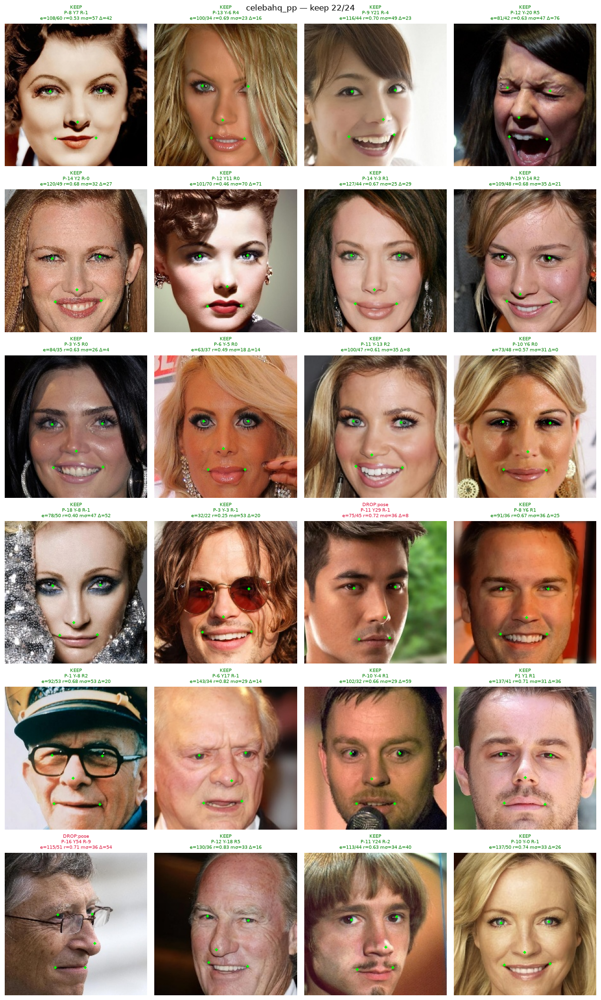

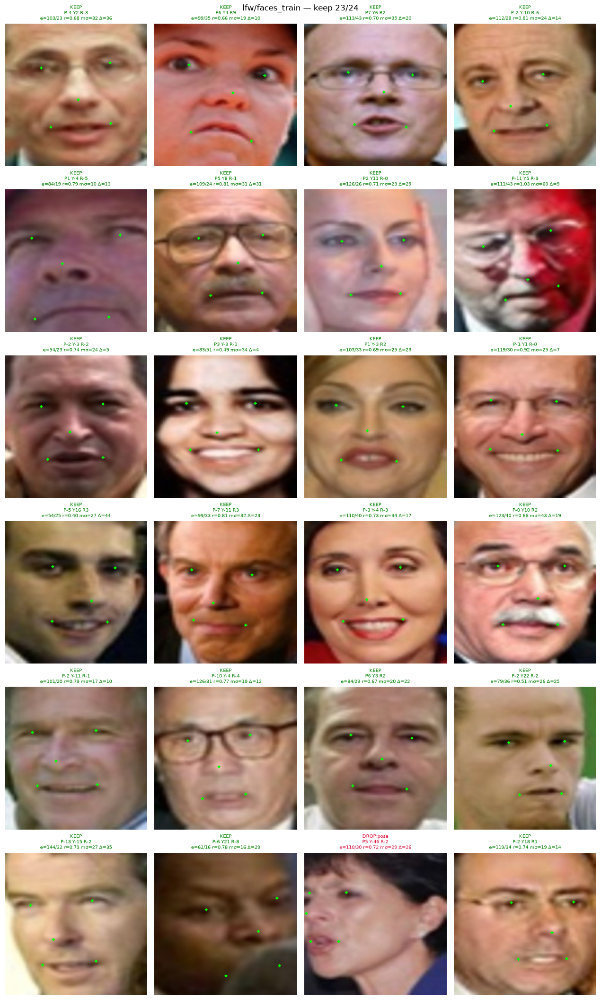

QA keep rates: celeba 22/24, lfw_train 23/24


In [26]:
def draw_kps(rgb: np.ndarray, kps: np.ndarray | None) -> np.ndarray:
    out = rgb.copy()
    if kps is None:
        return out
    for x, y in kps:
        cv2.circle(out, (int(x), int(y)), 2, (0, 255, 0), -1)
    return out


def qa_grid(paths: list[Path], title: str, n: int = QA_N, seed: int = 0):
    rng = np.random.default_rng(seed)
    n = min(n, len(paths))
    pick = sorted(rng.choice(len(paths), size=n, replace=False).tolist())
    cols = 4
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.6 * rows))
    axes = np.atleast_2d(axes)
    kept = 0
    for i, ax in enumerate(axes.ravel()):
        ax.axis("off")
        if i >= n:
            continue
        path = paths[pick[i]]
        bgr = cv2.imread(str(path))
        if bgr is None:
            ax.set_title("read_fail", fontsize=8)
            continue
        fr = evaluate_image(app, bgr)
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        rgb = draw_kps(rgb, fr.kps)
        ax.imshow(rgb)
        pose_s = (
            f"P{fr.pitch:.0f} Y{fr.yaw:.0f} R{fr.roll:.0f}"
            if fr.pitch is not None else "—"
        )
        eye_s = (
            f"e={fr.eye_mean:.0f}/{fr.eye_std:.0f} r={fr.eye_cheek_ratio:.2f}"
            if fr.eye_mean is not None else ""
        )
        m_delta = abs((fr.mouth_mean or 0.0) - (fr.cheek_mean or 0.0))
        m_s = f"mσ={fr.mouth_std:.0f} Δ={m_delta:.0f}" if fr.mouth_std is not None else ""
        mark = "KEEP" if fr.keep else f"DROP:{fr.reason}"
        if fr.keep:
            kept += 1
        ax.set_title(
            f"{mark}\n{pose_s}\n{eye_s} {m_s}",
            fontsize=7,
            color=("green" if fr.keep else "crimson"),
        )
    fig.suptitle(f"{title} — keep {kept}/{n}", fontsize=12)
    fig.tight_layout()
    plt.show()
    return kept, n


k1, n1 = qa_grid(celeba_files, "celebahq_pp", seed=7)
k2, n2 = qa_grid(list_images(LFW_ROOT / "faces_train"), "lfw/faces_train", seed=11)
print(f"QA keep rates: celeba {k1}/{n1}, lfw_train {k2}/{n2}")


### 4b. Exemplos forçados de descarte (+ referência da regra antiga de máscara)

Com `DROP_MASK=False`, **nenhuma** imagem deve ter `reason=="mask"`.
As grades “legacy mask” são só referência do que a regra antiga *teria* dropado — **não** são drops atuais.


scan QA metrics: 100%|██████████| 500/500 [00:16<00:00, 30.22it/s]


scan celeba (limit): {'pose': 64, 'keep': 436}
scan lfw_train (limit): {'keep': 478, 'pose': 21, 'sunglasses': 1}


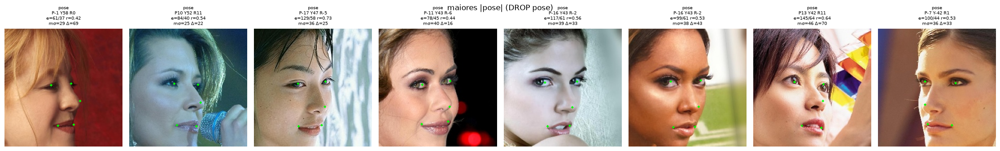

DROP sunglasses (celeba): nenhum caso
DROP mask: desligado (DROP_MASK=False); reason=mask count=0


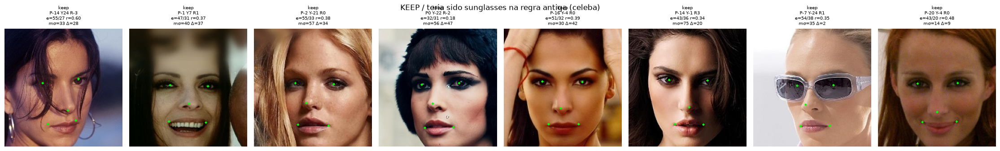

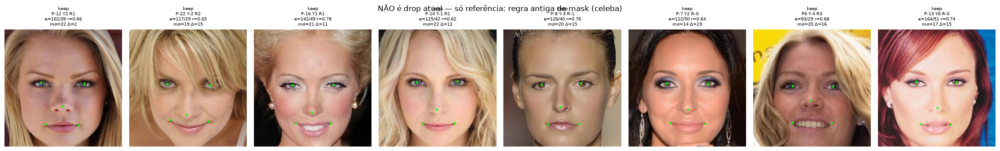

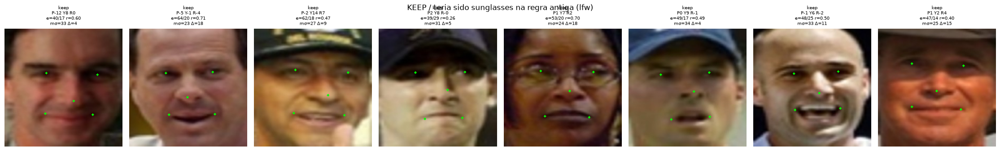

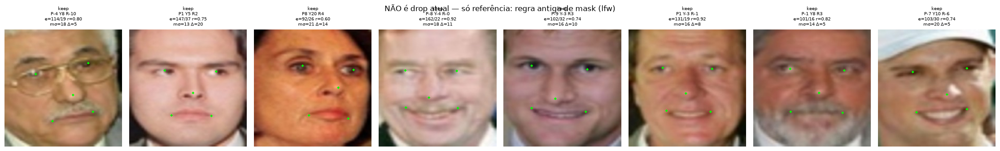

DROP_MASK=False | ref. legacy sun/mask evitados celeba: 8/12; lfw: 14/68


In [27]:
def scan_metrics(paths: list[Path], limit: int = 400) -> list[tuple[Path, FilterResult]]:
    out = []
    for p in tqdm(paths[:limit], desc="scan QA metrics"):
        bgr = cv2.imread(str(p))
        if bgr is None:
            continue
        out.append((p, evaluate_image(app, bgr)))
    return out


def show_cases(cases: list[tuple[Path, FilterResult]], title: str, max_n: int = 8):
    if not cases:
        print(f"{title}: nenhum caso")
        return
    n = min(max_n, len(cases))
    fig, axes = plt.subplots(1, n, figsize=(2.8 * n, 3.4))
    if n == 1:
        axes = [axes]
    for ax, (path, fr) in zip(axes, cases[:n]):
        bgr = cv2.imread(str(path))
        rgb = draw_kps(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), fr.kps)
        ax.imshow(rgb)
        ax.axis("off")
        pose_s = f"P{fr.pitch:.0f} Y{fr.yaw:.0f} R{fr.roll:.0f}" if fr.pitch is not None else "—"
        eye_s = (
            f"e={fr.eye_mean:.0f}/{fr.eye_std:.0f} r={fr.eye_cheek_ratio:.2f}"
            if fr.eye_mean is not None else ""
        )
        m_delta = abs((fr.mouth_mean or 0.0) - (fr.cheek_mean or 0.0))
        m_s = f"mσ={fr.mouth_std:.0f} Δ={m_delta:.0f}" if fr.mouth_std is not None else ""
        ax.set_title(f"{fr.reason}\n{pose_s}\n{eye_s}\n{m_s}", fontsize=7)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def legacy_sunglasses(fr: FilterResult) -> bool:
    """Heurística antiga (absoluta) — só para contrastar FPs evitados."""
    if fr.eye_mean is None or fr.eye_std is None:
        return False
    return fr.eye_mean < 55.0 or (fr.eye_mean < 65.0 and fr.eye_std < 22.0)


def legacy_mask(fr: FilterResult) -> bool:
    if fr.mouth_std is None or fr.mouth_mean is None or fr.cheek_mean is None:
        return False
    delta = abs(fr.mouth_mean - fr.cheek_mean)
    return fr.mouth_std < 16.0 or (fr.mouth_std < 22.0 and delta < 18.0)


scan_celeba = scan_metrics(celeba_files, limit=500)
scan_lfw = scan_metrics(list_images(LFW_ROOT / "faces_train"), limit=500)

for label, scan in [("celeba", scan_celeba), ("lfw_train", scan_lfw)]:
    reasons = Counter(fr.reason for _, fr in scan)
    print(f"scan {label} (limit):", dict(reasons))

pose_cases = sorted(
    [(p, fr) for p, fr in scan_celeba if fr.reason == "pose"],
    key=lambda t: -max(abs(t[1].pitch or 0), abs(t[1].yaw or 0), abs(t[1].roll or 0)),
)
sun_cases = sorted(
    [(p, fr) for p, fr in scan_celeba if fr.reason == "sunglasses"],
    key=lambda t: t[1].eye_mean if t[1].eye_mean is not None else 999,
)
mask_cases = [(p, fr) for p, fr in scan_celeba if fr.reason == "mask"]
if mask_cases and not DROP_MASK:
    print("AVISO: reason=mask com DROP_MASK=False — reexecute a célula de helpers (kernel desatualizado).")
# Referência: regra antiga de máscara (não é drop atual)
sun_fp_avoided = [
    (p, fr) for p, fr in scan_celeba
    if fr.keep and legacy_sunglasses(fr)
]
mask_fp_avoided = [
    (p, fr) for p, fr in scan_celeba
    if fr.keep and legacy_mask(fr)
]
sun_fp_avoided_lfw = [
    (p, fr) for p, fr in scan_lfw
    if fr.keep and legacy_sunglasses(fr)
]
mask_fp_avoided_lfw = [
    (p, fr) for p, fr in scan_lfw
    if fr.keep and legacy_mask(fr)
]

show_cases(pose_cases, "maiores |pose| (DROP pose)")
show_cases(sun_cases, "DROP sunglasses (celeba)")
if DROP_MASK:
    show_cases(mask_cases, "DROP mask (celeba)")
else:
    print(f"DROP mask: desligado (DROP_MASK=False); reason=mask count={len(mask_cases)}")
show_cases(sun_fp_avoided, "KEEP / teria sido sunglasses na regra antiga (celeba)")
show_cases(
    mask_fp_avoided,
    "NÃO é drop atual — só referência: regra antiga de mask (celeba)",
)
show_cases(sun_fp_avoided_lfw, "KEEP / teria sido sunglasses na regra antiga (lfw)")
show_cases(
    mask_fp_avoided_lfw,
    "NÃO é drop atual — só referência: regra antiga de mask (lfw)",
)
print(
    f"DROP_MASK={DROP_MASK} | ref. legacy sun/mask evitados celeba: "
    f"{len(sun_fp_avoided)}/{len(mask_fp_avoided)}; lfw: "
    f"{len(sun_fp_avoided_lfw)}/{len(mask_fp_avoided_lfw)}"
)


## 5. Batch — copiar imagens aceitas

**Execute só neste notebook** (evita perder o job se a sessão SSH cair). O filtro é **retomável**:
grava JSONL em `notebooks/outputs/filter_frontal/` e pula imagens já registradas.

1. Calibre thresholds na seção QA.
2. Defina `RUN_BATCH = True` na célula de setup e **reexecute o setup**.
3. Execute a célula abaixo. Pode interromper e reexecutar — continua de onde parou.
4. Se os datasets / `summary.json` já existirem e só quiser ver números, use a seção **6b**.


In [30]:
import json
from dataclasses import asdict

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


def place_file(src: Path, dst: Path, mode: str = COPY_MODE):
    dst.parent.mkdir(parents=True, exist_ok=True)
    if dst.exists():
        return
    if mode == "hardlink":
        try:
            dst.hardlink_to(src)
            return
        except OSError:
            pass
    shutil.copy2(src, dst)


def load_done(ckpt: Path) -> dict[str, str]:
    done: dict[str, str] = {}
    if not ckpt.exists():
        return done
    with ckpt.open("r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            rec = json.loads(line)
            done[rec["name"]] = rec["reason"]
    return done


def filter_folder(src_dir: Path, dst_dir: Path, label: str, ckpt: Path) -> dict:
    """Filtro retomável: JSONL de decisões + skip de nomes já processados."""
    files = list_images(src_dir)
    done = load_done(ckpt)
    counts: Counter[str] = Counter(done.values())
    pending = [p for p in files if p.name not in done]
    print(f"[{label}] total={len(files)} already={len(done)} pending={len(pending)}")

    with ckpt.open("a", encoding="utf-8") as fout:
        for path in tqdm(pending, desc=label):
            bgr = cv2.imread(str(path))
            if bgr is None:
                reason, keep = "read_fail", False
                rec = {"name": path.name, "reason": reason, "keep": False}
            else:
                fr = evaluate_image(app, bgr)
                reason, keep = fr.reason, fr.keep
                rec = {"name": path.name, **asdict(fr)}
            counts[reason] += 1
            fout.write(json.dumps(rec, ensure_ascii=False) + "\n")
            fout.flush()
            if keep:
                place_file(path, dst_dir / path.name)

    total = sum(counts.values())
    kept = counts.get("keep", 0)
    discarded = total - kept
    summary = {
        "label": label,
        "src": str(src_dir),
        "dst": str(dst_dir),
        "total": total,
        "kept": kept,
        "discarded": discarded,
        "discard_rate": (discarded / total) if total else 0.0,
        "reasons": dict(counts),
        "checkpoint": str(ckpt),
    }
    print(
        f"[{label}] kept={kept}/{total} ({100 * kept / total:.2f}%)  "
        f"discarded={discarded}  reasons={dict(counts)}"
    )
    return summary


summaries = []
if not RUN_BATCH:
    print("RUN_BATCH=False — pulando cópia.")
    print("Para rodar o batch: RUN_BATCH=True no setup → reexecute setup → reexecute esta célula.")
    print(f"Summary existente? {(CHECKPOINT_DIR / 'summary.json').exists()}")
else:
    summaries.append(
        filter_folder(CELEBA_IN, CELEBA_OUT, "celebahq_pp", CHECKPOINT_DIR / "celebahq_pp.jsonl")
    )
    for split in LFW_EXPECTED:
        summaries.append(
            filter_folder(
                LFW_ROOT / split,
                LFW_OUT / split,
                f"lfw/{split}",
                CHECKPOINT_DIR / f"lfw_{split}.jsonl",
            )
        )
    out_json = CHECKPOINT_DIR / "summary.json"
    out_json.write_text(json.dumps(summaries, indent=2), encoding="utf-8")
    print("Wrote", out_json)


[celebahq_pp] total=29995 already=29995 pending=0


celebahq_pp: 0it [00:00, ?it/s]

[celebahq_pp] kept=24722/29995 (82.42%)  discarded=5273  reasons={'pose': 3466, 'keep': 24722, 'sunglasses': 1082, 'mask': 721, 'no_face': 4}


[lfw/faces_train] total=10586 already=10586 pending=0


lfw/faces_train: 0it [00:00, ?it/s]

[lfw/faces_train] kept=8226/10586 (77.71%)  discarded=2360  reasons={'mask': 1456, 'keep': 8226, 'sunglasses': 456, 'pose': 440, 'no_face': 8}


[lfw/faces_test] total=2647 already=2647 pending=0


lfw/faces_test: 0it [00:00, ?it/s]

[lfw/faces_test] kept=2029/2647 (76.65%)  discarded=618  reasons={'keep': 2029, 'sunglasses': 114, 'pose': 118, 'mask': 383, 'no_face': 3}
Wrote /home/dcarvalho/Lightweight-Face-De-identification/notebooks/outputs/filter_frontal/summary.json


## 6. Resumo final + sanity `FaceImageFolder`

Se acabou de rodar o batch (`summaries` preenchido), a célula abaixo imprime a tabela.
Se `RUN_BATCH=False`, use **6b** para carregar um `summary.json` já existente.


In [31]:
def print_summaries(rows: list[dict]):
    header = f"{'split':22} {'total':>7} {'kept':>7} {'disc':>7} {'disc%':>7}  reasons"
    print(header)
    print("-" * len(header))
    tot_t = tot_k = 0
    for s in rows:
        reasons = {k: v for k, v in s["reasons"].items() if k != "keep"}
        print(
            f"{s['label']:22} {s['total']:7d} {s['kept']:7d} {s['discarded']:7d} "
            f"{100 * s['discard_rate']:6.2f}%  {reasons}"
        )
        tot_t += s["total"]
        tot_k += s["kept"]
    print(f"\nTOTAL kept: {tot_k} / {tot_t}  ({100 * tot_k / tot_t:.2f}%)")


if summaries:
    print_summaries(summaries)
else:
    print("Sem summaries em memória (batch não rodou nesta sessão). Veja seção 6b.")

# Sanity sempre que as pastas de saída existirem
for root in (CELEBA_OUT, LFW_OUT / "faces_train", LFW_OUT / "faces_test"):
    if not root.exists() or not list_images(root):
        print(f"SKIP sanity (vazio/ausente): {root}")
        continue
    ds = FaceImageFolder(root, image_size=224)
    x, p = ds[0]
    print(f"FaceImageFolder OK  n={len(ds)}  tensor={tuple(x.shape)}  ex={Path(p).name}  root={root}")


split                    total    kept    disc   disc%  reasons
---------------------------------------------------------------
celebahq_pp              29995   24722    5273  17.58%  {'pose': 3466, 'sunglasses': 1082, 'mask': 721, 'no_face': 4}
lfw/faces_train          10586    8226    2360  22.29%  {'mask': 1456, 'sunglasses': 456, 'pose': 440, 'no_face': 8}
lfw/faces_test            2647    2029     618  23.35%  {'sunglasses': 114, 'pose': 118, 'mask': 383, 'no_face': 3}

TOTAL kept: 34977 / 43228  (80.91%)
FaceImageFolder OK  n=24722  tensor=(3, 224, 224)  ex=img_00001.jpg  root=/mnt/study-data/dcarvalho/datasets/celebahq_pp_frontal
FaceImageFolder OK  n=8226  tensor=(3, 224, 224)  ex=img_000003.jpg  root=/mnt/study-data/dcarvalho/datasets/lfw_frontal/faces_train
FaceImageFolder OK  n=2029  tensor=(3, 224, 224)  ex=img_000000.jpg  root=/mnt/study-data/dcarvalho/datasets/lfw_frontal/faces_test


### 6b. Carregar `summary.json` existente (sem reprocessar)

Útil se o batch já rodou (neste notebook ou via `scripts/filter_frontal_datasets.py`) e você só quer inspecionar contagens.


In [ ]:
summary_path = CHECKPOINT_DIR / "summary.json"
if LOAD_EXISTING_SUMMARY and summary_path.exists():
    loaded = json.loads(summary_path.read_text(encoding="utf-8"))
    print(f"Carregado: {summary_path}")
    print_summaries(loaded)
elif not summary_path.exists():
    print(f"Ainda não existe: {summary_path}")
else:
    print("LOAD_EXISTING_SUMMARY=False — pulando.")


## Notas para DECISIONS.md

- Oclusão: óculos ativo (`eye_max`+`eye_std`+`eye/cheek`). **Máscara off** via `DROP_MASK=False`
  (heurística preservada em `mask_flag` + thresholds `MOUTH_*`; religar = `DROP_MASK=True` + reexecutar setup/helpers).
- Batch antigo ainda pode ter counts `mask` no `summary.json` — reprocessar após validar QA.
